# Customer Churn Prediction

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


## 1. Data Understanding

In [2]:
df=pd.read_csv("E:\Download\Churn_ML_Proj\WA_Fn-UseC_-Telco-Customer-Churn.csv")
df

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes


In [3]:
df.shape

(7043, 21)

In [4]:
#Statistical summary of the dataframe
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


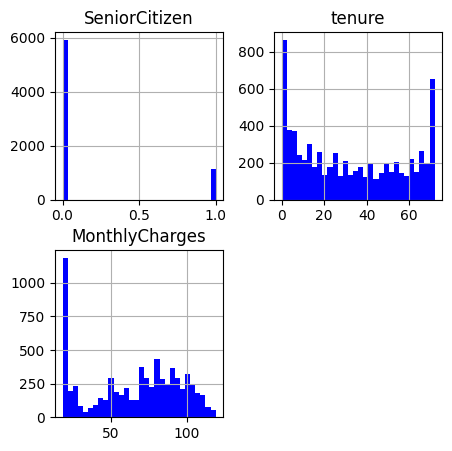

In [5]:
df.hist(bins=30,figsize=(5,5),color='b')
plt.show()

In [6]:
#get the correction matrix
corr_matrix = df.corr(numeric_only=True)
corr_matrix

,SeniorCitizen,tenure,MonthlyCharges
SeniorCitizen,1.000000,0.016567,0.220173
tenure,0.016567,1.000000,0.247900
MonthlyCharges,0.220173,0.247900,1.000000


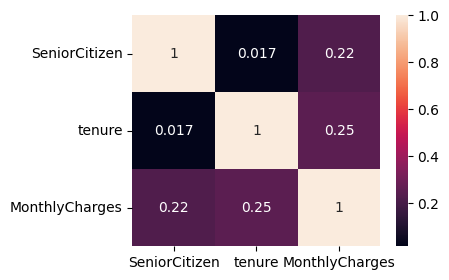

In [7]:
plt.figure(figsize=(4,3))
sns.heatmap(corr_matrix,annot=True)
plt.show()

In [8]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df.nunique()

customerID          7043
gender                 2
SeniorCitizen          2
Partner                2
Dependents             2
tenure                73
PhoneService           2
MultipleLines          3
InternetService        3
OnlineSecurity         3
OnlineBackup           3
DeviceProtection       3
TechSupport            3
StreamingTV            3
StreamingMovies        3
Contract               3
PaperlessBilling       2
PaymentMethod          4
MonthlyCharges      1585
TotalCharges        6531
Churn                  2
dtype: int64

In [12]:
df['gender'].value_counts()

gender
Male      3555
Female    3488
Name: count, dtype: int64

In [13]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

In [14]:
df['TotalCharges'].describe()

count    7032.000000
mean     2283.300441
std      2266.771362
min        18.800000
25%       401.450000
50%      1397.475000
75%      3794.737500
max      8684.800000
Name: TotalCharges, dtype: float64

In [15]:
df['Contract'].value_counts()

Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64

In [16]:
df['Contract'].describe()

count               7043
unique                 3
top       Month-to-month
freq                3875
Name: Contract, dtype: object

In [17]:
df['InternetService'].value_counts()

InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

In [18]:
df['PaymentMethod'].value_counts()

PaymentMethod
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: count, dtype: int64

In [19]:
df[['tenure','MonthlyCharges','TotalCharges']].describe()

,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7032.000000
mean,32.371149,64.761692,2283.300441
std,24.559481,30.090047,2266.771362
min,0.000000,18.250000,18.800000
25%,9.000000,35.500000,401.450000
50%,29.000000,70.350000,1397.475000
75%,55.000000,89.850000,3794.737500
max,72.000000,118.750000,8684.800000


In [20]:
df.columns.tolist()

['customerID',
 'gender',
 'SeniorCitizen',
 'Partner',
 'Dependents',
 'tenure',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod',
 'MonthlyCharges',
 'TotalCharges',
 'Churn']

In [21]:
df[df['TotalCharges'].isnull()][
    ['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']
]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


## 2. Exploratory Data Analysis(EDA)

#### A. Customer Churn Distribution

In [22]:
df['Churn'].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [23]:
df['Churn'].value_counts(normalize=True)*100

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

Text(0, 0.5, 'Number of Customers')

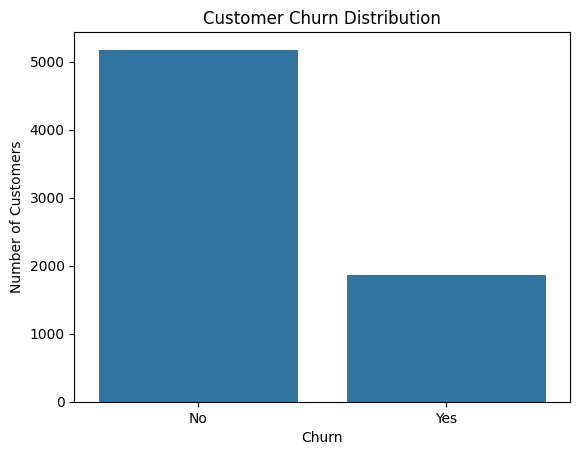

In [24]:
sns.countplot(data=df,x='Churn')

plt.title('Customer Churn Distribution')
plt.xlabel('Churn')
plt.ylabel('Number of Customers')

Insight:The dataset contains 7,043 customers. About 73.46% of customers stayed, while 26.54% churned. This shows that the target variable is somewhat imbalanced, with fewer customers in the churned class.

### B.Contract Type vs Churn

In [25]:
pd.crosstab(df['Contract'],df['Churn'])

Churn,No,Yes
Contract,,
Month-to-month,2220,1655
One year,1307,166
Two year,1647,48


In [26]:
churn_rate=pd.crosstab(df['Contract'],df['Churn'],normalize='index')*100
churn_rate

Churn,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


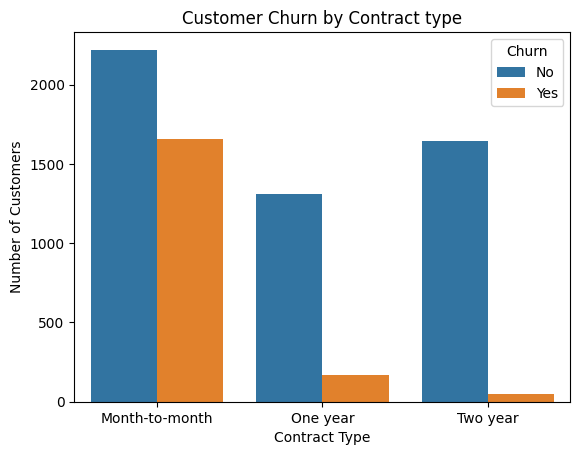

In [27]:
sns.countplot(data=df,x='Contract',hue='Churn')
plt.title('Customer Churn by Contract type')
plt.xlabel('Contract Type')
plt.ylabel('Number of Customers')
plt.show()

 Insight: Contract type is strongly associated with customer churn. Month-to-month customers have the highest churn rate (42.71%), while customers with two-year contracts have the lowest churn rate (2.83%).

### C.payment Method vs Churn

In [28]:
pd.crosstab(df['PaymentMethod'],df['Churn'])

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),1286,258
Credit card (automatic),1290,232
Electronic check,1294,1071
Mailed check,1304,308


In [29]:
payment_churn_rate=pd.crosstab(df['PaymentMethod'],df['Churn'],normalize='index')*100
payment_churn_rate

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.290155,16.709845
Credit card (automatic),84.756899,15.243101
Electronic check,54.714588,45.285412
Mailed check,80.893300,19.106700


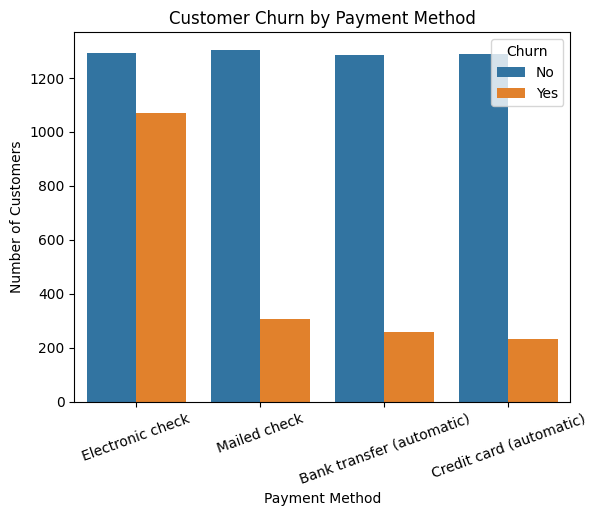

In [30]:
sns.countplot(data=df,x='PaymentMethod',hue='Churn')
plt.title('Customer Churn by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Number of Customers')
plt.xticks(rotation=20)
plt.show()

### D.Tenure vs Churn 

In [31]:
df.groupby('Churn')['tenure'].mean()

Churn
No     37.569965
Yes    17.979133
Name: tenure, dtype: float64

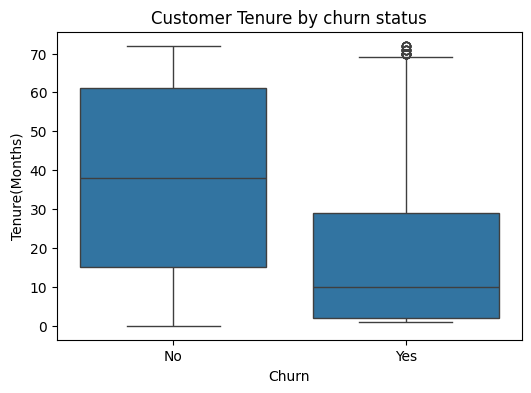

In [32]:
plt.figure(figsize=(6,4))
sns.boxplot(data=df,x='Churn',y='tenure')

plt.title('Customer Tenure by churn status')
plt.xlabel('Churn')
plt.ylabel('Tenure(Months)')
plt.show()

In [33]:
df['TenureGroup'] = pd.cut(
    df['tenure'],
    bins=[0, 12, 24, 48, 72],
    labels=['0-12 months', '13-24 months', '25-48 months', '49-72 months']
)

In [34]:
tenure_churn_rate = pd.crosstab(
    df['TenureGroup'],
    df['Churn'],
    normalize='index'
) * 100

tenure_churn_rate

Churn,No,Yes
TenureGroup,,
0-12 months,52.321839,47.678161
13-24 months,71.289062,28.710938
25-48 months,79.611041,20.388959
49-72 months,90.486824,9.513176


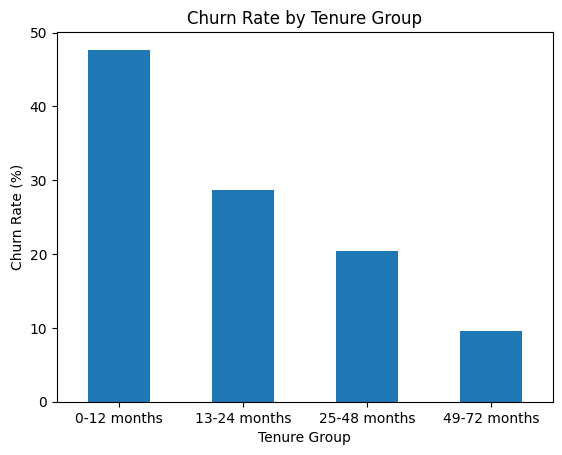

In [35]:
tenure_churn_rate['Yes'].plot(kind='bar')
plt.title('Churn Rate by Tenure Group')
plt.xlabel('Tenure Group')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=0)
plt.show()

### E. Monthly Charges vs Churn 

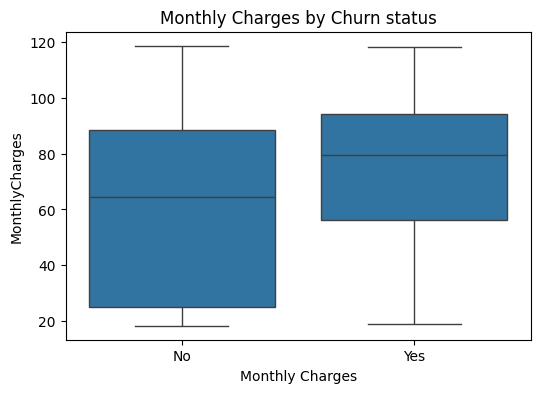

In [36]:
plt.figure(figsize=(6,4))
sns.boxplot(data=df,x='Churn',y='MonthlyCharges')
plt.title('Monthly Charges by Churn status')
plt.xlabel('Monthly Charges')
plt.show()

In [37]:
df.groupby('Churn')['MonthlyCharges'].mean()

Churn
No     61.265124
Yes    74.441332
Name: MonthlyCharges, dtype: float64

### F. Total Charges vs Churn 

In [38]:
df.groupby('Churn')['TotalCharges'].mean()

Churn
No     2555.344141
Yes    1531.796094
Name: TotalCharges, dtype: float64

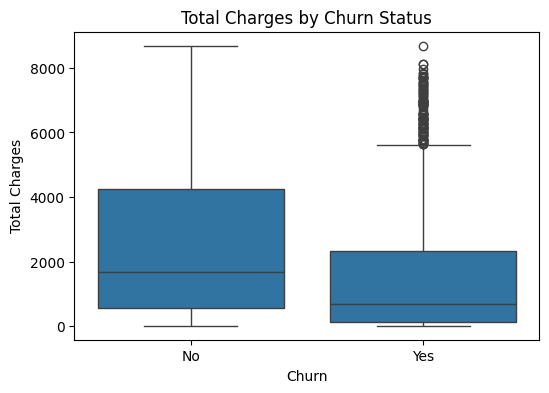

In [39]:
plt.figure(figsize=(6,4))

sns.boxplot(data=df, x='Churn', y='TotalCharges')

plt.title('Total Charges by Churn Status')
plt.xlabel('Churn')
plt.ylabel('Total Charges')
plt.show()

### G. Internet Service vs Churn 

In [40]:
pd.crosstab(df['InternetService'],df['Churn'])

Churn,No,Yes
InternetService,,
DSL,1962,459
Fiber optic,1799,1297
No,1413,113


In [41]:
internet_churn_rate=pd.crosstab(df['InternetService'],
                                df['Churn'],
                                normalize='index')*100
internet_churn_rate

Churn,No,Yes
InternetService,,
DSL,81.040892,18.959108
Fiber optic,58.107235,41.892765
No,92.595020,7.404980


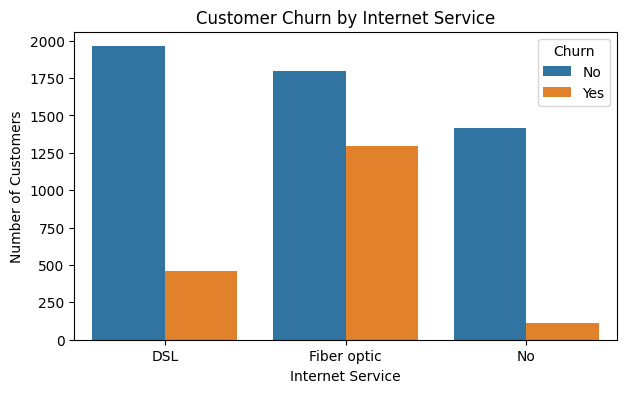

In [42]:
plt.figure(figsize=(7,4))

sns.countplot(
    data=df,
    x='InternetService',
    hue='Churn'
)

plt.title('Customer Churn by Internet Service')
plt.xlabel('Internet Service')
plt.ylabel('Number of Customers')
plt.show()

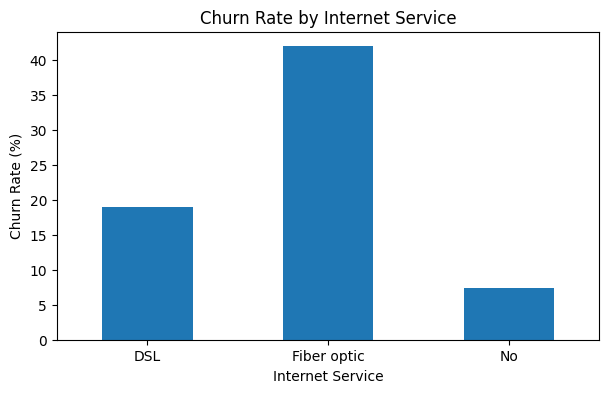

In [43]:
internet_churn_rate['Yes'].plot(
    kind='bar',
    figsize=(7,4)
)

plt.title('Churn Rate by Internet Service')
plt.xlabel('Internet Service')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=0)
plt.show()

### H. Tech Support vs Churn

In [44]:
pd.crosstab(df['TechSupport'],df['Churn'])

Churn,No,Yes
TechSupport,,
No,2027,1446
No internet service,1413,113
Yes,1734,310


In [45]:
techsupport_churn_rate=pd.crosstab(df['TechSupport'],
                                   df['Churn'],normalize='index')*100
techsupport_churn_rate

Churn,No,Yes
TechSupport,,
No,58.364526,41.635474
No internet service,92.595020,7.404980
Yes,84.833659,15.166341


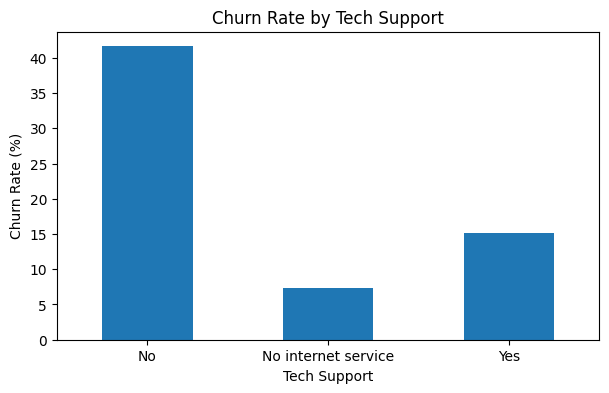

In [46]:
techsupport_churn_rate['Yes'].plot(
    kind='bar',
    figsize=(7,4)
)

plt.title('Churn Rate by Tech Support')
plt.xlabel('Tech Support')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=0)
plt.show()



## I. Online Security vs Churn 

In [47]:
pd.crosstab(df['OnlineSecurity'],df['Churn'])

Churn,No,Yes
OnlineSecurity,,
No,2037,1461
No internet service,1413,113
Yes,1724,295


In [48]:
onlinesecurity_churn_rate=pd.crosstab(df['OnlineSecurity'],
    df['Churn'],normalize='index')*100
onlinesecurity_churn_rate

Churn,No,Yes
OnlineSecurity,,
No,58.233276,41.766724
No internet service,92.595020,7.404980
Yes,85.388806,14.611194


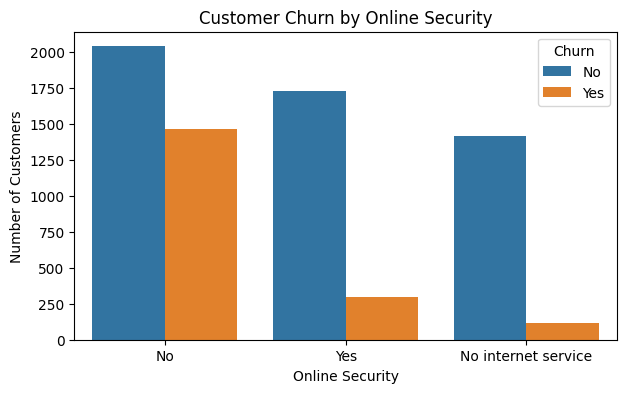

In [49]:
plt.figure(figsize=(7,4))

sns.countplot(
    data=df,
    x='OnlineSecurity',
    hue='Churn'
)

plt.title('Customer Churn by Online Security')
plt.xlabel('Online Security')
plt.ylabel('Number of Customers')
plt.show()

## 3. Data Prepocessing

In [50]:
#Handle missing values
df[df['TotalCharges'].isnull()][['tenure','MonthlyCharges','TotalCharges','Churn']]

,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,NaN,No
753,0,20.25,NaN,No
936,0,80.85,NaN,No
1082,0,25.75,NaN,No
1340,0,56.05,NaN,No
3331,0,19.85,NaN,No
3826,0,25.35,NaN,No
4380,0,20.00,NaN,No
5218,0,19.70,NaN,No
6670,0,73.35,NaN,No


In [51]:
#Separate feature and target
#the model learns from customer information(x) to predict whether the customer churns(y)

x=df.drop(columns=['customerID','Churn','TenureGroup'])

y=df['Churn'].map({'No':0,'Yes':1})

print("X shape:",x.shape)
print("y shape:",y.shape)

print("\nTarget distribution:")
print(y.value_counts())



X shape: (7043, 19)
y shape: (7043,)

Target distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [52]:
#Split training and testing data

from sklearn.model_selection import train_test_split

x_train,x_test,y_train,y_test=train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("x_train: ",x_train.shape)
print("x_test:",x_test.shape)
print("y_train:",y_train.shape)
print("y_test:",y_test.shape)

x_train:  (5634, 19)
x_test: (1409, 19)
y_train: (5634,)
y_test: (1409,)


In [53]:

# Identify numerical and categorical columns

numerical_features = x_train.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = x_train.select_dtypes(
    include=['str']
).columns.tolist()

print("Numerical features:", numerical_features)
print("\nCategorical features:", categorical_features)

Numerical features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [54]:
#Build the preprocessing pipeline

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder,StandardScaler

#Numerical prepocessing 
numerical_transformer=Pipeline(steps=[('imputer',SimpleImputer(strategy='median')),
                                      ('scaler',StandardScaler())
                                     ])

#Categorical preprocessing

categorical_transformer=Pipeline(steps=[('imputer',SimpleImputer(strategy='most_frequent')),
                                        ('onehot',OneHotEncoder(handle_unknown='ignore'))
                                       ])

preprocessor=ColumnTransformer(
    transformers=[
        ('num',numerical_transformer,numerical_features),
        ('cat',categorical_transformer,categorical_features)
    ]
)


In [55]:
#Test the preprocessing pipeline

x_train_processed = preprocessor.fit_transform(x_train)
x_test_processed = preprocessor.transform(x_test)

print("Processed training data:", x_train_processed.shape)
print("Processed testing data:", x_test_processed.shape)

Processed training data: (5634, 45)
Processed testing data: (1409, 45)


## 4. Model Training and Evaluation

### 4.1 Logistic Regression-Baseline Model

In [56]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
#Create the model
lr_model=LogisticRegression(max_iter=1000)

#Train the model
lr_model.fit(x_train_processed,y_train)

#predict on unseen test data

y_pred=lr_model.predict(x_test_processed)

#Evaluate performance

print("Accuracy:",accuracy_score(y_test,y_pred))
print("\n Classification Report:")
print(classification_report(y_test,y_pred))


Accuracy: 0.8055358410220014

 Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



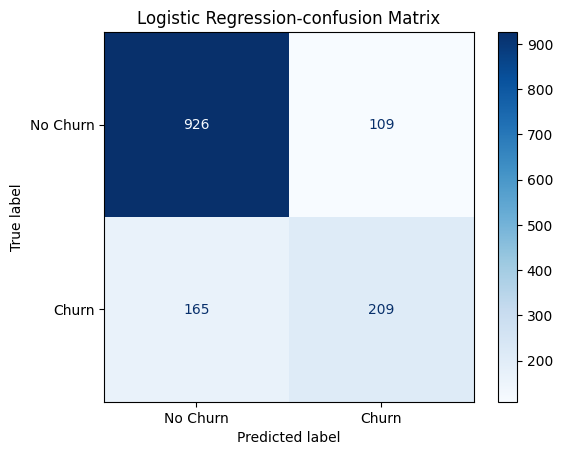

In [57]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

cm=confusion_matrix(y_test,y_pred)

disp=ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['No Churn','Churn']

)

disp.plot(cmap='Blues',values_format='d')
plt.title('Logistic Regression-confusion Matrix')
plt.show()

### 4.2 Train Random Forest

In [58]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
# create the model

rf_model= RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight='balanced'
)

#2. Train the model
rf_model.fit(x_train_processed,y_train)

#3.Predict on test data
rf_pred=rf_model.predict(x_test_processed)

#4. Evaluate 
print("Random Forest Accuracy: ",
      accuracy_score(y_test,rf_pred))
print("\n Classification report: ")
print(classification_report(y_test, rf_pred))

Random Forest Accuracy:  0.7636621717530163

 Classification report: 
              precision    recall  f1-score   support

           0       0.86      0.82      0.84      1035
           1       0.55      0.62      0.58       374

    accuracy                           0.76      1409
   macro avg       0.70      0.72      0.71      1409
weighted avg       0.77      0.76      0.77      1409



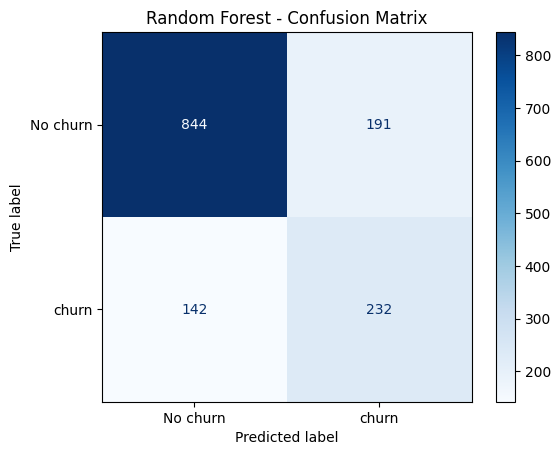

In [59]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_pred,
    display_labels=['No churn','churn'],
    cmap='Blues',
    values_format='d'

)

plt.title('Random Forest - Confusion Matrix')
plt.show()

### 4.3 XGBoost

In [60]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [61]:
import xgboost as xgb
print("XGBoost version:",xgb.__version__)

XGBoost version: 3.4.1


### XGBoost Model Evalutaion

In [62]:
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score,classification_report

xgb_model=XGBClassifier(
    n_estimators=200,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric='logloss',
    random_state=42
)

# train model
xgb_model.fit(x_train_processed,y_train)

#predict
xgb_pred=xgb_model.predict(x_test_processed)

# Evaluate

print("XGBoost Accuracy:",
      accuracy_score(y_test,xgb_pred))
print(classification_report(y_test,xgb_pred))

XGBoost Accuracy: 0.8048261178140526
              precision    recall  f1-score   support

           0       0.84      0.90      0.87      1035
           1       0.67      0.53      0.59       374

    accuracy                           0.80      1409
   macro avg       0.75      0.72      0.73      1409
weighted avg       0.80      0.80      0.80      1409



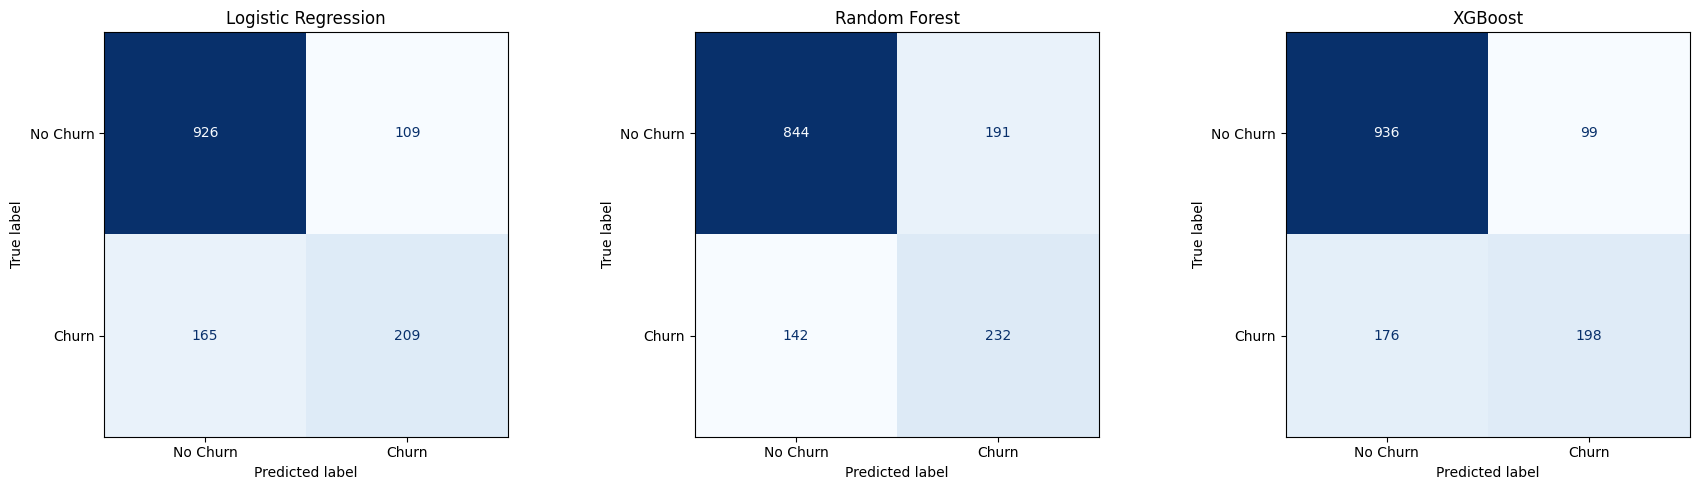

In [63]:
#Confusion Matrix Comparison

from sklearn.metrics import ConfusionMatrixDisplay

models = [
    ("Logistic Regression", y_pred),
    ("Random Forest", rf_pred),
    ("XGBoost", xgb_pred)
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, predictions) in zip(axes, models):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        labels=[0, 1],
        display_labels=["No Churn", "Churn"],
        values_format="d",
        cmap="Blues",
        ax=ax,
        colorbar=False
    )
    ax.set_title(name)

plt.tight_layout()
plt.show()

## 5. Model Perfomance Comparison

### 5.1 Performance Comparison Table

In [64]:
#Create the comparison table
from sklearn.metrics import(
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

results=pd.DataFrame({
    'Model':['Logistic Regression','Random Forest','XGBoost'
            ],
    'Accuracy':[
        accuracy_score(y_test,y_pred),
        accuracy_score(y_test,rf_pred),
        accuracy_score(y_test,xgb_pred)
    ],
    'Churn Precision':[
        precision_score(y_test,y_pred),
        precision_score(y_test,rf_pred),
        precision_score(y_test,xgb_pred)
    ],
    'Churn Recall':[
        recall_score(y_test,y_pred),
        recall_score(y_test,rf_pred),
        recall_score(y_test,xgb_pred)
    ],

    'Churn F1-score':[
        f1_score(y_test,y_pred),
        f1_score(y_test,rf_pred),
        f1_score(y_test,xgb_pred)

    ]

})

results.round(3)

,Model,Accuracy,Churn Precision,Churn Recall,Churn F1-score
0,Logistic Regression,0.806,0.657,0.559,0.604
1,Random Forest,0.764,0.548,0.620,0.582
2,XGBoost,0.805,0.667,0.529,0.590


## 5.2 Performance Comparison Visualization

The bar chart compares the performance of Logistic Regression, Random Forest, and XGBoost across four evaluation metrics: accuracy, churn precision, churn recall, and churn F1-score.

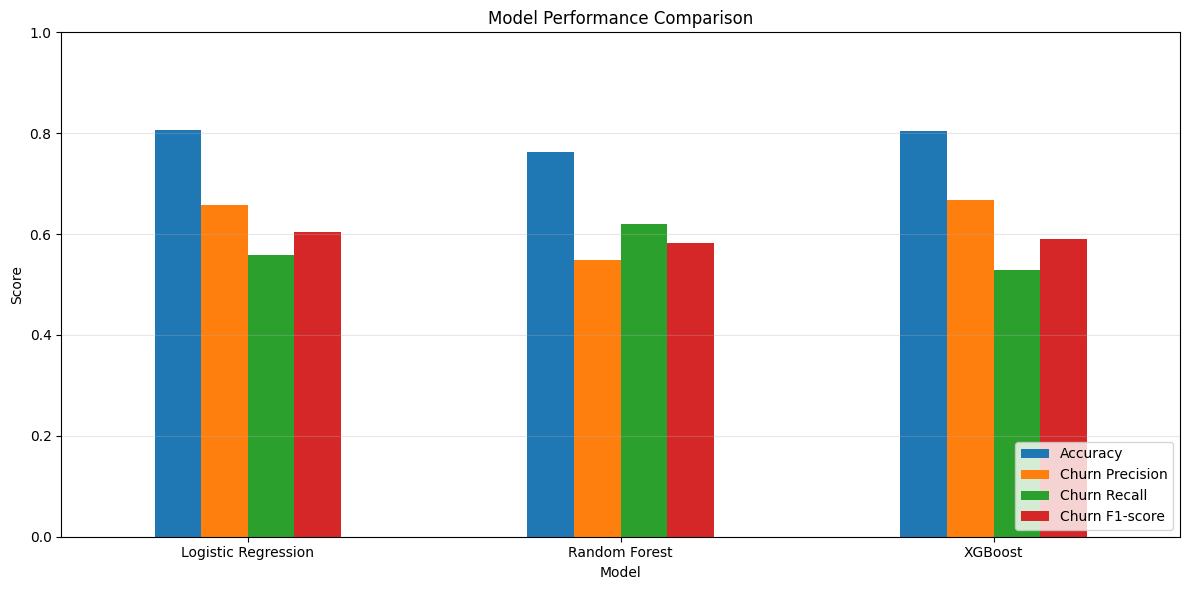

In [65]:
metrics=['Accuracy',
         'Churn Precision',
         'Churn Recall',
         'Churn F1-score'
        ]
results.set_index('Model')[metrics].plot(
    kind='bar',
    figsize=(12,6)
)

plt.title('Model Performance Comparison')
plt.ylabel('Score')
plt.xlabel('Model')
plt.ylim(0,1)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.grid(axis='y',alpha=0.3)
plt.tight_layout()
plt.show()


## 5.3 Comparative Analysis

The comparison shows that each model has different strengths. Logistic Regression achieved the highest accuracy (80.55%) and churn F1-score (0.60), indicating a relatively balanced performance. Random Forest achieved the highest churn recall (62%), making it more effective at identifying customers who are likely to leave, although it generated more false-positive predictions. XGBoost achieved the highest churn precision (66.7%) but the lowest churn recall (52.9%), meaning its positive predictions were relatively reliable, but it missed more actual churners. Overall, Logistic Regression is a strong baseline candidate, while the final model selection should depend on cross-validation results and the business costs associated with missed churners and unnecessary retention offers.

## 6 Cross-Validation and Model Selection


In [66]:

## Cross-validation Setup
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Keep the churn proportion similar across folds
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Build complete pipelines so preprocessing is refitted
# separately inside each cross-validation training fold
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),

    'Random Forest': RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight='balanced'
    ),

    'XGBoost': XGBClassifier(
        n_estimators=200,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric='logloss',
        random_state=42
    )
}

scoring = {
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1'
}

cv_results = []

for name, model in models.items():
    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])

    scores = cross_validate(
        pipeline,
        x_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    cv_results.append({
        'Model': name,
        'Mean Accuracy': scores['test_accuracy'].mean(),
        'Mean Churn Precision': scores['test_precision'].mean(),
        'Mean Churn Recall': scores['test_recall'].mean(),
        'Mean Churn F1-score': scores['test_f1'].mean(),
        'F1 Std Dev': scores['test_f1'].std()
    })

cv_results_df = pd.DataFrame(cv_results)

cv_results_df.round(3)

,Model,Mean Accuracy,Mean Churn Precision,Mean Churn Recall,Mean Churn F1-score,F1 Std Dev
0,Logistic Regression,0.802,0.653,0.543,0.592,0.030
1,Random Forest,0.776,0.568,0.645,0.604,0.024
2,XGBoost,0.805,0.670,0.528,0.590,0.025


In [67]:
## Final Condidate Model
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

final_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight='balanced'
    ))
])

final_model.fit(x_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainde

Final Candidate: Random Forest
Test Accuracy: 0.7636621717530163
              precision    recall  f1-score   support

    No Churn       0.86      0.82      0.84      1035
       Churn       0.55      0.62      0.58       374

    accuracy                           0.76      1409
   macro avg       0.70      0.72      0.71      1409
weighted avg       0.77      0.76      0.77      1409



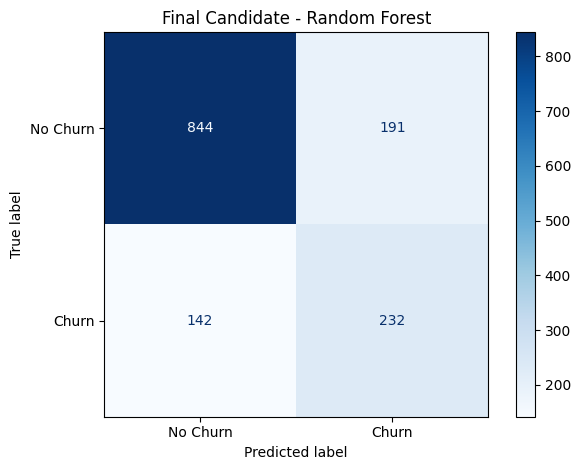

In [68]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

final_pred = final_model.predict(x_test)

print("Final Candidate: Random Forest")
print("Test Accuracy:", accuracy_score(y_test, final_pred))
print(classification_report(
    y_test,
    final_pred,
    target_names=['No Churn', 'Churn']
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    final_pred,
    display_labels=['No Churn', 'Churn'],
    values_format='d',
    cmap='Blues'
)

plt.title('Final Candidate - Random Forest')
plt.tight_layout()
plt.show()

    

## 7 Conclusion and Feature Improvements

This project developed a machine learning workflow to predict customer churn using the Telco Customer Churn dataset. The workflow included data cleaning, exploratory data analysis, feature preprocessing, model training, and evaluation.

Three classification algorithms—Logistic Regression, Random Forest, and XGBoost—were compared using accuracy, precision, recall, F1-score, confusion matrices, and five-fold stratified cross-validation. Logistic Regression achieved the highest accuracy on the initial test comparison (80.55%), while Random Forest achieved the highest mean churn recall (64.5%) and mean churn F1-score (0.604) during cross-validation.

Based on these cross-validation results, Random Forest was selected as the leading candidate for churn detection. Its test-set accuracy was 76.37%, with a churn recall of 62% and churn F1-score of 0.58. These results suggest that the model can identify a useful proportion of customers who may leave, although false-positive predictions remain a limitation.

Future Improvements

_Tune model hyperparameters using cross-validation.

_Investigate decision-threshold adjustment to balance precision and recall.

_Explore additional features and feature importance to understand the drivers of churn.

_Evaluate the financial impact of false positives and false negatives.

_Develop a Power BI dashboard to communicate churn patterns and business insights.

_Consider deploying an interactive prediction application after further validation.

## 8 Feature Importance Analysis


This section examines the features that contribute most to the Random Forest model's predictions. Understanding feature importance can help identify customer characteristics associated with churn and provide useful insights for customer retention strategies. Feature importance indicates how the model uses features; it does not establish causation.

### 8.1 Extracting Feature Imortance

In [69]:
# Get the fitted preprocessing and Random Forest steps

fitted_preprocessor=final_model.named_steps['preprocessor']
rf_classifier=final_model.named_steps['classifier']

#Get feature names after preprocessing

feature_names=fitted_preprocessor.get_feature_names_out()

#Extract importance scores

importance_df=pd.DataFrame({
    'Feature':feature_names,
    'Importance': rf_classifier.feature_importances_

})

# sort from most to least important
importance_df=importance_df.sort_values(
    by='Importance',
    ascending=False,
).reset_index(drop=True)

importance_df.head(15)



,Feature,Importance
0,num__TotalCharges,0.142587
1,num__tenure,0.132618
2,num__MonthlyCharges,0.121383
3,cat__Contract_Month-to-month,0.070944
4,cat__OnlineSecurity_No,0.038223
5,cat__Contract_Two year,0.035218
6,cat__TechSupport_No,0.033847
7,cat__PaymentMethod_Electronic check,0.029494
8,cat__InternetService_Fiber optic,0.028561
9,cat__OnlineBackup_No,0.017756


### 8.2 Top 15 Important Feature


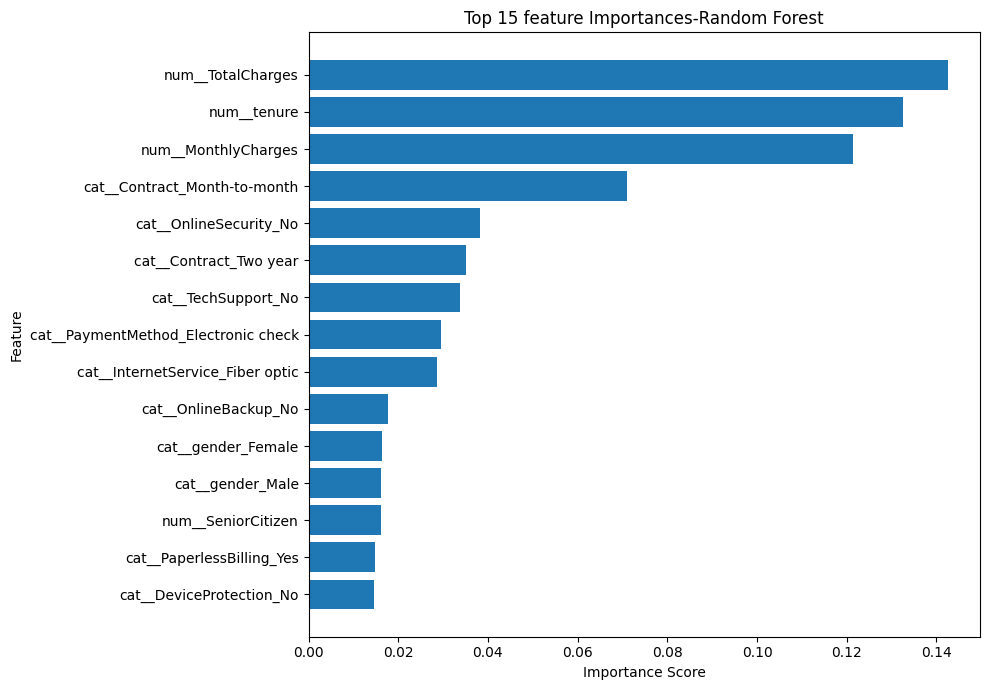

In [71]:
top_features=importance_df.head(15).sort_values(
    by='Importance',
    ascending=True
)

plt.figure(figsize=(10,7))

plt.barh(
    top_features['Feature'],
    top_features['Importance']

)

plt.title('Top 15 feature Importances-Random Forest')
plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()


Feature importance analysis was conducted to identify the features that contributed most to the Random Forest model's predictions. The results show that **TotalCharges (14.26%)**, **tenure (13.26%)**, and **MonthlyCharges (12.14%)** were the three most important features. Together, they accounted for approximately 39.65% of the model's total feature importance.

Contract type was also influential, particularly month-to-month contracts (7.09%) and two-year contracts (3.52%). Other notable features included the absence of online security (3.82%), the absence of technical support (3.38%), electronic-check payments (2.95%), and fiber-optic internet service (2.86%).

These findings are consistent with several patterns observed during exploratory data analysis, particularly the higher churn rate among month-to-month customers and customers without technical support. The results suggest that customer tenure, billing characteristics, and contract type are useful features for predicting churn.

However, feature importance describes how the model uses features to make predictions; it does not establish causal relationships. Further analysis, such as permutation importance or SHAP, could provide additional insight into how individual features influence model predictions.